In [84]:
import pandas as pd
import seaborn as sns

In [86]:
titanic = pd.read_csv('C:/Users/1/train.csv')

In [3]:
titanic.tail(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
881,882,0,3,"Markun, Mr. Johann",male,33.0,0,0,349257,7.8958,NaN,S
882,883,0,3,"Dahlberg, Miss. Gerda Ulrika",female,22.0,0,0,7552,10.5167,NaN,S
883,884,0,2,"Banfield, Mr. Frederick James",male,28.0,0,0,C.A./SOTON 34068,10.5000,NaN,S
884,885,0,3,"Sutehall, Mr. Henry Jr",male,25.0,0,0,SOTON/OQ 392076,7.0500,NaN,S
885,886,0,3,"Rice, Mrs. William (Margaret Norton)",female,39.0,0,5,382652,29.1250,NaN,Q
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.7500,NaN,Q


In [7]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [9]:
titanic.duplicated().sum()

0

In [11]:
titanic.isna().sum() 

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [13]:
titanic.PassengerId.count()

891

1. Survived - выжил пассажир или нет

In [15]:
titanic.Survived.value_counts(normalize=True,dropna=False).mul(100).round()    # выжило 342 человека из 891 (38%)

Survived
0    62.0
1    38.0
Name: proportion, dtype: float64

2. Pclass - каким классом путешествовал пассажир

In [17]:
titanic.Pclass.value_counts()   

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

In [19]:
titanic.Pclass.value_counts(normalize=True,dropna=False).mul(100).round()  # бОльшая часть пассажиров (55%) путешествовала классом 3 

Pclass
3    55.0
1    24.0
2    21.0
Name: proportion, dtype: float64

<Axes: xlabel='Pclass', ylabel='count'>

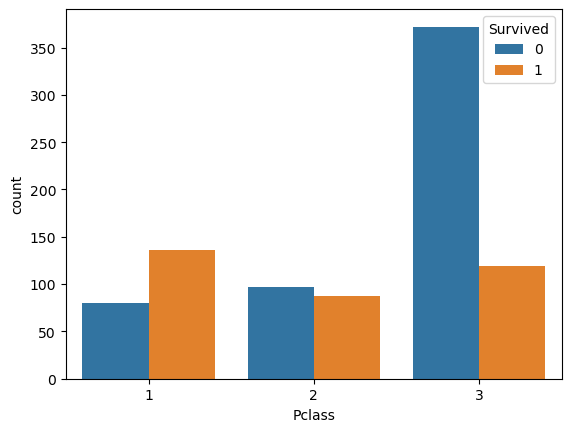

In [21]:
sns.countplot(x='Pclass',data = titanic, hue='Survived')   # в 1 классе было больше выживших, чем во 2 и 3 классе     

3. Sex

In [23]:
titanic.Sex.value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

In [25]:
titanic.Sex.value_counts(normalize=True,dropna=False).mul(100).round()  # доля мужчин на борту 65%, женщин 35%

Sex
male      65.0
female    35.0
Name: proportion, dtype: float64

In [27]:
titanic.query('Sex == "female" and Survived == 1').shape[0] / titanic.query('Sex == "female"').shape[0]

0.7420382165605095

In [29]:
titanic.query('Sex == "male" and Survived == 1').shape[0] / titanic.query('Sex == "male"').shape[0]

0.18890814558058924

<Axes: xlabel='Sex', ylabel='count'>

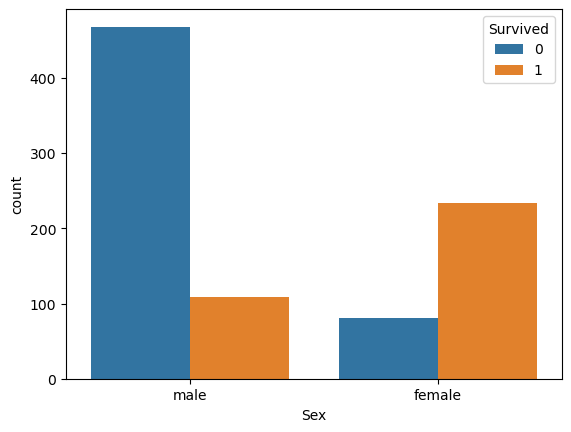

In [702]:
sns.countplot(x='Sex',data = titanic, hue='Survived')    # среди мужчин выжили всего 19%, среди женщин выжили 74%

4. Age

в колонке 177 пропущенных значений, заменим их на среднее по признакам Пол и Класс

In [31]:
titanic.groupby(['Sex','Pclass']).Age.mean()

Sex     Pclass
female  1         34.611765
        2         28.722973
        3         21.750000
male    1         41.281386
        2         30.740707
        3         26.507589
Name: Age, dtype: float64

In [88]:
titanic['Age'] = titanic.groupby(['Sex','Pclass'])['Age'].transform(lambda x: x.fillna(x.mean()))

In [90]:
titanic.Age.isna().sum()

0

In [92]:
titanic.Age.describe()    # средний возраст пассажиров 29 лет, самому младшему было 5 месяцев, самому старшему 80 лет

count    891.000000
mean      29.318643
std       13.281103
min        0.420000
25%       21.750000
50%       26.507589
75%       36.000000
max       80.000000
Name: Age, dtype: float64

In [39]:
titanic[titanic.Age==0.420000]   # малыш Alexander выжил

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
803,804,1,3,"Thomas, Master. Assad Alexander",male,0.42,0,1,2625,8.5167,NaN,C


добавим колонку с возрастными группами

In [94]:
interval_range = pd.interval_range(start=0,
                                   freq=10,
                                   end=80)

titanic['Age_range'] = pd.cut(titanic['Age'],
                       bins=interval_range)
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Age_range
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,"(20, 30]"
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,"(30, 40]"
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,"(20, 30]"
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,"(30, 40]"
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,"(30, 40]"


<Axes: xlabel='Age_range', ylabel='count'>

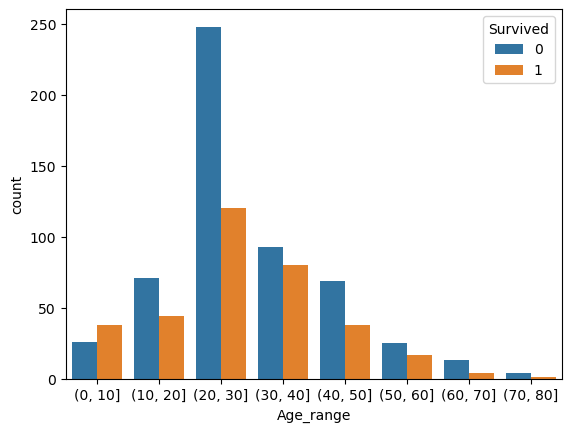

In [720]:
sns.countplot(x='Age_range',data = titanic, hue='Survived')    # большая часть детей в возрасте до 10 лет выжили, в остальных возрастных группах число жертв было больше, чем выживших

5. SibSp - братьев, сестер или супругов у данного пассажира
Parch- родителей или детей у данного пассажира

In [44]:
titanic.SibSp.unique()

array([1, 0, 3, 4, 2, 5, 8], dtype=int64)

In [46]:
titanic.Parch.unique()

array([0, 1, 2, 5, 3, 4, 6], dtype=int64)

<Axes: xlabel='have_a_family', ylabel='count'>

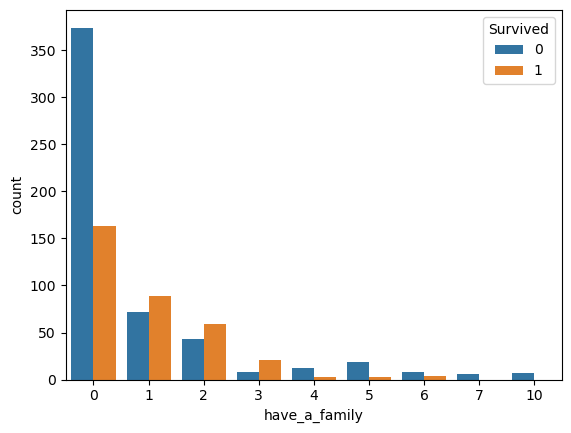

In [96]:
titanic['have_a_family'] = titanic.SibSp + titanic.Parch
titanic.query('have_a_family == 0').shape[0] / titanic.shape[0]
sns.countplot(x='have_a_family',data = titanic, hue='Survived')     
# бОльшая часть пассажиров (60%) путешествовали в одиночку и по числу выживших их больше всего (примерно 160 человек)
# но шансы на выживание превысили смертность только у тех, кто путешествовал небольшими семьями (с 1-3 близкими)
# у людей с 4 и более родными на борту шансы на выживания сильно ниже...


6. Fare - тариф\стоимость

In [50]:
titanic.Fare.describe()

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64

есть смысл посмотреть выбросы

<Axes: ylabel='Fare'>

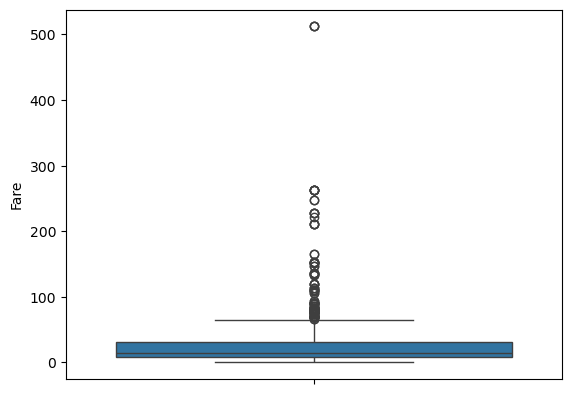

In [53]:
sns.boxplot(titanic.Fare)

In [55]:
a=titanic.Fare.quantile(0.25)
b=titanic.Fare.quantile(0.75)

In [57]:
a-1.5*(b-a), b+1.5*(b-a)

(-26.724, 65.6344)

In [59]:
titanic[(titanic['Fare']>65)].shape[0] / titanic.shape[0]   # доля тех, кто заплатил очень высокую цену за билет = 13%, не будем их удалять

0.13019079685746351

In [98]:
titanic['Fare_category'] = pd.cut(titanic['Fare'],
                       bins=[0,8,15,31,513],
                       labels=['low', 'medium_low','medium_hight','hight'])
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Age_range,have_a_family,Fare_category
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,"(20, 30]",1,low
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,"(30, 40]",1,hight
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,"(20, 30]",0,low
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,"(30, 40]",1,hight
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,"(30, 40]",0,medium_low


<Axes: xlabel='Fare_category', ylabel='count'>

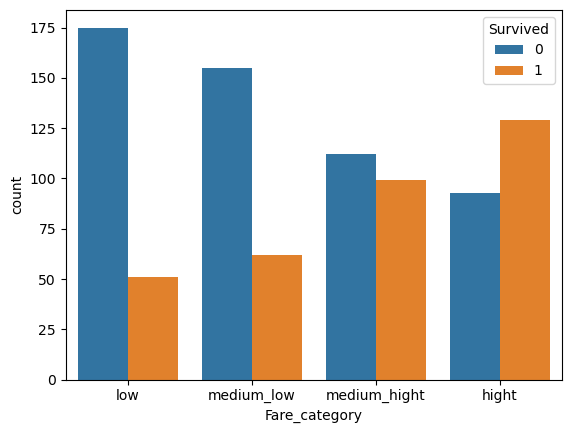

In [745]:
sns.countplot(x='Fare_category',data = titanic, hue='Survived')   # есть прямая зависимость между ценой билета и выживаемостью, чем больше заплатил пассажир, чем выше шансы на спасение

<Axes: xlabel='Fare_category', ylabel='count'>

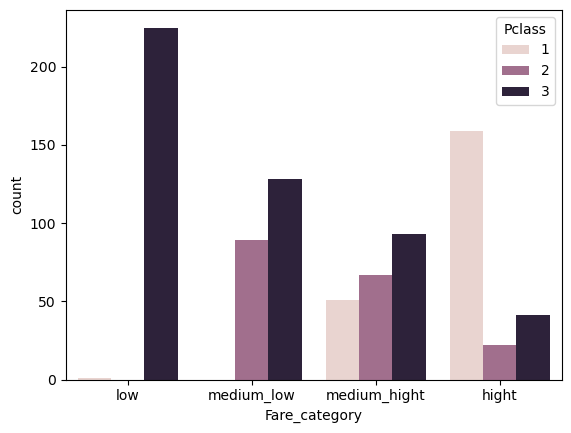

In [63]:
Permutation Importance , Feature importancesns.countplot(x='Fare_category',data = titanic, hue='Pclass')  # интересное ценообразование (может последние билеты): за 1 класс всегда платили цену выше среднего, но есть и те кто заплатил очень высокую за 3 класс  

7. Embarked - город посадки пассажира

колонка имеет 2 пропущенных значения, заполним модой

In [100]:
titanic['Embarked'] = titanic['Embarked'].fillna(titanic['Embarked'].mode()[0])

In [67]:
titanic.Embarked.value_counts()

Embarked
S    646
C    168
Q     77
Name: count, dtype: int64

In [69]:
(titanic.Embarked.value_counts(normalize=True,dropna=False)*100).round()   # 72% пассажиров совершили посадку из города Southampton, 19% из города Cherbourg, остальные из Queenstown

Embarked
S    73.0
C    19.0
Q     9.0
Name: proportion, dtype: float64

<Axes: xlabel='Embarked', ylabel='count'>

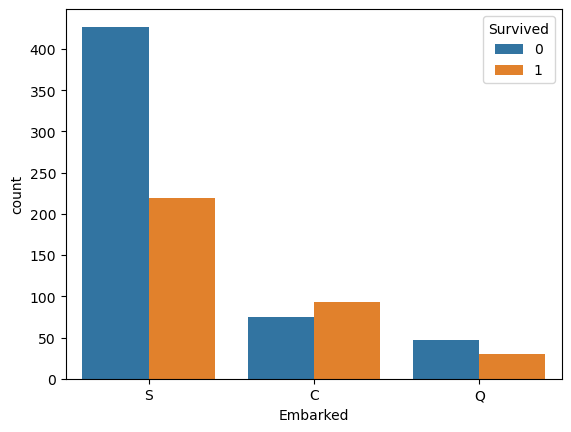

In [758]:
sns.countplot(x='Embarked',data = titanic, hue='Survived')   # но люди с посадкой в Cherbourg имели более высокие шансы выжить

удалим колонки Name, Ticket и Cabin (и новые)- не несут прогнозного смысла

In [102]:
titanic.drop(columns=['Name','Ticket','Cabin','Age_range','have_a_family','Fare_category'], inplace=True)

In [104]:
titanic

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,1,0,3,male,22.00,1,0,7.2500,S
1,2,1,1,female,38.00,1,0,71.2833,C
2,3,1,3,female,26.00,0,0,7.9250,S
3,4,1,1,female,35.00,1,0,53.1000,S
4,5,0,3,male,35.00,0,0,8.0500,S
...,...,...,...,...,...,...,...,...,...
886,887,0,2,male,27.00,0,0,13.0000,S
887,888,1,1,female,19.00,0,0,30.0000,S
888,889,0,3,female,21.75,1,2,23.4500,S
889,890,1,1,male,26.00,0,0,30.0000,C


кодируем категориальные переменные

In [106]:
titanic = pd.get_dummies(titanic)

In [108]:
titanic

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,22.00,1,0,7.2500,False,True,False,False,True
1,2,1,1,38.00,1,0,71.2833,True,False,True,False,False
2,3,1,3,26.00,0,0,7.9250,True,False,False,False,True
3,4,1,1,35.00,1,0,53.1000,True,False,False,False,True
4,5,0,3,35.00,0,0,8.0500,False,True,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,27.00,0,0,13.0000,False,True,False,False,True
887,888,1,1,19.00,0,0,30.0000,True,False,False,False,True
888,889,0,3,21.75,1,2,23.4500,True,False,False,False,True
889,890,1,1,26.00,0,0,30.0000,False,True,True,False,False


Градиентный бустинг

In [110]:
from sklearn.ensemble import GradientBoostingClassifier

In [112]:
model = GradientBoostingClassifier(random_state=0)

In [114]:
model.fit(titanic[['Pclass','Age','SibSp','Parch','Fare','Sex_female','Sex_male','Embarked_C','Embarked_Q','Embarked_S']].values.reshape(-1,10), y=titanic['Survived'].values)

GradientBoostingClassifier(random_state=0)

In [116]:
model.classes_

array([0, 1], dtype=int64)

Загружаем тестовую выборку

In [118]:
titanic_test = pd.read_csv('C:/Users/1/test.csv')

In [120]:
titanic_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Pclass       418 non-null    int64  
 2   Name         418 non-null    object 
 3   Sex          418 non-null    object 
 4   Age          332 non-null    float64
 5   SibSp        418 non-null    int64  
 6   Parch        418 non-null    int64  
 7   Ticket       418 non-null    object 
 8   Fare         417 non-null    float64
 9   Cabin        91 non-null     object 
 10  Embarked     418 non-null    object 
dtypes: float64(2), int64(4), object(5)
memory usage: 36.1+ KB


заполним пропуски

In [123]:
titanic_test.groupby(['Sex','Pclass']).Age.mean()

Sex     Pclass
female  1         41.333333
        2         24.376552
        3         23.073400
male    1         40.520000
        2         30.940678
        3         24.525104
Name: Age, dtype: float64

In [125]:
titanic_test['Age'] = titanic_test.groupby(['Sex','Pclass'])['Age'].transform(lambda x: x.fillna(x.mean()))

In [127]:
titanic_test['Fare'] = titanic_test['Fare'].fillna(titanic_test['Fare'].median())

In [129]:
titanic_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Pclass       418 non-null    int64  
 2   Name         418 non-null    object 
 3   Sex          418 non-null    object 
 4   Age          418 non-null    float64
 5   SibSp        418 non-null    int64  
 6   Parch        418 non-null    int64  
 7   Ticket       418 non-null    object 
 8   Fare         418 non-null    float64
 9   Cabin        91 non-null     object 
 10  Embarked     418 non-null    object 
dtypes: float64(2), int64(4), object(5)
memory usage: 36.1+ KB


удалим колонки Name, Ticket и Cabin

In [132]:
titanic_test.drop(columns=['Name','Ticket','Cabin'], inplace=True)

In [134]:
titanic_test = pd.get_dummies(titanic_test)

In [136]:
titanic_test

,PassengerId,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,892,3,34.500000,0,0,7.8292,False,True,False,True,False
1,893,3,47.000000,1,0,7.0000,True,False,False,False,True
2,894,2,62.000000,0,0,9.6875,False,True,False,True,False
3,895,3,27.000000,0,0,8.6625,False,True,False,False,True
4,896,3,22.000000,1,1,12.2875,True,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...
413,1305,3,24.525104,0,0,8.0500,False,True,False,False,True
414,1306,1,39.000000,0,0,108.9000,True,False,True,False,False
415,1307,3,38.500000,0,0,7.2500,False,True,False,False,True
416,1308,3,24.525104,0,0,8.0500,False,True,False,False,True


прогоняем тестовую выборку

In [138]:
titanic_test['Predicted']=model.predict(titanic_test[['Pclass','Age','SibSp','Parch','Fare','Sex_female','Sex_male','Embarked_C','Embarked_Q','Embarked_S']].values.reshape(-1,10))

In [140]:
titanic_test

,PassengerId,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Predicted
0,892,3,34.500000,0,0,7.8292,False,True,False,True,False,0
1,893,3,47.000000,1,0,7.0000,True,False,False,False,True,0
2,894,2,62.000000,0,0,9.6875,False,True,False,True,False,0
3,895,3,27.000000,0,0,8.6625,False,True,False,False,True,0
4,896,3,22.000000,1,1,12.2875,True,False,False,False,True,0
...,...,...,...,...,...,...,...,...,...,...,...,...
413,1305,3,24.525104,0,0,8.0500,False,True,False,False,True,0
414,1306,1,39.000000,0,0,108.9000,True,False,True,False,False,1
415,1307,3,38.500000,0,0,7.2500,False,True,False,False,True,0
416,1308,3,24.525104,0,0,8.0500,False,True,False,False,True,0


Сделала исскуственно тест выборку

In [142]:
titanic_sample = titanic.sample(891)

In [144]:
titanic_sample.head()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
824,825,0,3,2.000000,4,1,39.6875,False,True,False,False,True
97,98,1,1,23.000000,0,1,63.3583,False,True,True,False,False
567,568,0,3,29.000000,0,4,21.0750,True,False,False,False,True
656,657,0,3,26.507589,0,0,7.8958,False,True,False,False,True
42,43,0,3,26.507589,0,0,7.8958,False,True,True,False,False


добавляю прогноз

In [147]:
titanic_sample['Predicted']=model.predict(titanic_sample[['Pclass','Age','SibSp','Parch','Fare','Sex_female','Sex_male','Embarked_C','Embarked_Q','Embarked_S']].values.reshape(-1,10))

In [149]:
titanic_sample

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Predicted
824,825,0,3,2.000000,4,1,39.6875,False,True,False,False,True,0
97,98,1,1,23.000000,0,1,63.3583,False,True,True,False,False,1
567,568,0,3,29.000000,0,4,21.0750,True,False,False,False,True,0
656,657,0,3,26.507589,0,0,7.8958,False,True,False,False,True,0
42,43,0,3,26.507589,0,0,7.8958,False,True,True,False,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
143,144,0,3,19.000000,0,0,6.7500,False,True,False,True,False,0
27,28,0,1,19.000000,3,2,263.0000,False,True,False,False,True,0
94,95,0,3,59.000000,0,0,7.2500,False,True,False,False,True,0
200,201,0,3,28.000000,0,0,9.5000,False,True,False,False,True,0


In [151]:
pd.crosstab(titanic_sample['Predicted'], titanic_sample['Survived'])

Survived,0,1
Predicted,,
0,522,70
1,27,272


In [153]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import precision_recall_fscore_support

In [155]:
accuracy_score(titanic_sample['Predicted'],titanic_sample['Survived'])

0.8911335578002245

In [157]:
precision_score(titanic_sample['Predicted'],titanic_sample['Survived'], average=None, zero_division=1)

array([0.95081967, 0.79532164])

In [159]:
recall_score(titanic_sample['Predicted'],titanic_sample['Survived'], average=None, zero_division=1)

array([0.88175676, 0.909699  ])

In [161]:
precision_recall_fscore_support(titanic_sample['Predicted'], titanic_sample['Survived']) 

(array([0.95081967, 0.79532164]),
 array([0.88175676, 0.909699  ]),
 array([0.91498685, 0.84867395]),
 array([592, 299], dtype=int64))

In [165]:
submission = titanic_test[['PassengerId', 'Predicted']]

In [185]:
submission = submission.rename(columns = {'Predicted':'Survived'})

In [187]:
submission.to_csv('submission.csv', index=False)